# Notebook 12 – Business Insights

# Question 1 – Identify Important Patterns

Identify important patterns in the dataset that may be useful from a business perspective.

## Step 1 – Understand the concept

A pattern is a repeated or noticeable behavior in the data.

In business analysis, identifying patterns helps us understand customer behavior and identify areas that may require attention.


## Step 2 – Demonstrate the concept

We can compare the average tenure of customers who stayed with customers who churned.

If churned customers have lower average tenure, it may indicate that newer customers are more likely to leave.


## Step 3 – Implementation the concept

Calculate the average tenure for each churn category.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

Dataset Loaded Successfully!
Dataset Shape: (7043, 21)


In [12]:
tenure_churn = (
    df.groupby("Churn")["tenure"]
    .mean()
)

print("Average Tenure by Churn:")
print(tenure_churn.round(2))

Average Tenure by Churn:
Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64


## Observation

Compare the average tenure of customers who stayed and customers who churned.

## Insight

If churned customers have lower average tenure, it indicates that newer customers may be more likely to leave.

This suggests that the business should focus on customer onboarding and early-stage retention.

# Question 2 – Identify Important Trends

Identify important trends in customer behavior that may provide useful business information.

## Step 1 – Understand the concept

A trend represents a general direction or change observed in the data.

Identifying trends helps businesses understand how customer behavior changes across different values or time periods.


## Step 2 – Demonstrate the concept

We can analyze the average MonthlyCharges across different customer tenure levels.

This helps us understand whether customer charges change as tenure increases.


## Step 3 – Implementation the concept

Group customers by tenure and calculate their average MonthlyCharges.

In [13]:
tenure_charges = (
    df.groupby("tenure")["MonthlyCharges"]
    .mean()
    .reset_index()
)

print(tenure_charges.head(10))

   tenure  MonthlyCharges
0       0       41.418182
1       1       50.485808
2       2       57.206303
3       3       58.015000
4       4       57.432670
5       5       61.003759
6       6       56.589091
7       7       59.642366
8       8       57.245122
9       9       62.564706


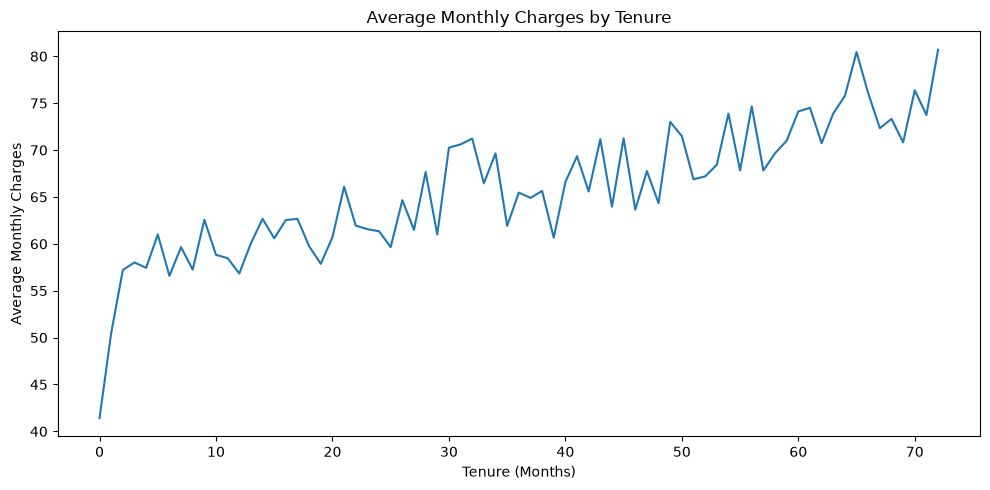

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(
    tenure_charges["tenure"],
    tenure_charges["MonthlyCharges"]
)

plt.title("Average Monthly Charges by Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Average Monthly Charges")

plt.tight_layout()
plt.show()

## Observation

Observe how average MonthlyCharges change across different tenure levels.

## Insight

The trend helps identify whether customer spending changes throughout the customer lifecycle.

This can help the business understand pricing patterns and customer value across different tenure groups.

# Question 3 – Identify Important Relationships

Identify important relationships between business-related variables.

## Step 1 – Understand the concept

A relationship shows how two variables are associated with each other.

Understanding relationships can help businesses identify customer groups that behave differently.

## Step 2 – Demonstrate the concept

We can analyze the relationship between Contract type and Churn.

This helps us determine whether churn behavior differs across contract types.


## Step 3 – Implementation the concept

Calculate the churn rate for each Contract type.

In [15]:
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Churn Rate by Contract Type:")
print(contract_churn.round(2))

Churn Rate by Contract Type:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


## Observation

Compare the churn rates across the different Contract types.

## Insight

If one Contract type has a noticeably higher churn rate, it represents a potentially higher-risk customer segment.

The business can investigate the reasons behind the higher churn and develop suitable retention strategies.

# Question 4 – Identify Anomalies

Identify unusual observations or anomalies that may require business investigation.

## Step 1 – Understand the concept

An anomaly is an observation that differs significantly from the general pattern of the data.

An anomaly may represent an unusual customer, a genuine business case, or a data-quality issue.


## Step 2 – Demonstrate the concept

We can identify unusual MonthlyCharges values using the IQR method.

These observations can then be investigated further.


## Step 3 – Implementation the concept

Calculate the IQR and identify potential MonthlyCharges anomalies.

In [16]:
Q1 = df["MonthlyCharges"].quantile(0.25)
Q3 = df["MonthlyCharges"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

anomalies = df[
    (df["MonthlyCharges"] < lower_bound) |
    (df["MonthlyCharges"] > upper_bound)
]

print("Number of Potential Anomalies:", len(anomalies))

print("\nPotential Anomalies:")
print(
    anomalies[
        ["customerID", "MonthlyCharges", "Contract", "Churn"]
    ].head()
)

Number of Potential Anomalies: 0

Potential Anomalies:
Empty DataFrame
Columns: [customerID, MonthlyCharges, Contract, Churn]
Index: []


## Observation

The identified customers have MonthlyCharges values outside the normal IQR range.

## Insight

These unusual values may represent premium customers, unusual service combinations, or possible data-quality issues.

They should be investigated rather than automatically removed.

# Question 5 – Identify Potential Business Problems

Identify potential business problems from the EDA results.

## Step 1 – Understand the concept

EDA can reveal business problems such as:

- High customer churn
- High-risk customer segments
- Uneven customer distribution
- Customer retention issues
- Unusual customer behavior


## Step 2 – Demonstrate the concept

Customer churn is an important business problem because losing customers can reduce recurring revenue and increase customer acquisition costs.


## Step 3 – Implementation the concept

Calculate the overall customer churn rate.

In [17]:
overall_churn = (
    (df["Churn"] == "Yes").mean() * 100
)

print("Overall Churn Rate:", round(overall_churn, 2), "%")

Overall Churn Rate: 26.54 %


## Observation

The churn rate represents the proportion of customers who have left the service.

## Insight

Customer churn is a potential business problem because customer loss can affect recurring revenue.

The business should identify the main characteristics of customers who churn and develop targeted retention strategies.

# Question 6 – Identify Interesting Customer Segments

Identify customer segments that show noticeably different business behavior.

## Step 1 – Understand the concept

A customer segment is a group of customers that share a common characteristic.

Segment analysis helps businesses identify high-risk, high-value, or unique customer groups.


## Step 2 – Demonstrate the concept

We can compare churn rates across different InternetService categories.

This helps identify segments with different levels of customer retention.


## Step 3 – Implementation the concept

Calculate the churn rate for each InternetService category.

In [18]:
internet_churn = (
    df.groupby("InternetService")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Churn Rate by Internet Service:")
print(internet_churn.round(2))

Churn Rate by Internet Service:
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64


## Observation

Compare the churn rates across the InternetService categories.

## Insight

A segment with a noticeably higher churn rate can be considered a higher-risk customer segment.

The business can investigate this segment further and design targeted retention strategies.

# Question 7 – Identify Potential Business Opportunities

Identify potential opportunities that can be derived from the EDA results.

## Step 1 – Understand the concept

A business opportunity is an area where the company may be able to improve customer retention, revenue, customer satisfaction, or service adoption.


## Step 2 – Demonstrate the concept

We can analyze Contract and InternetService together to identify customer segments with relatively low or high churn rates.


## Step 3 – Implementation the concept

Calculate the churn rate for each Contract and InternetService combination.

In [19]:
segment_analysis = (
    df.groupby(["Contract", "InternetService"])["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

segment_analysis = segment_analysis.sort_values("ChurnRate")

print("Contract and Internet Service Segments:")
print(segment_analysis.round(2))

Contract and Internet Service Segments:
         Contract InternetService  ChurnRate
8        Two year              No       0.78
6        Two year             DSL       1.91
5        One year              No       2.47
7        Two year     Fiber optic       7.23
3        One year             DSL       9.30
2  Month-to-month              No      18.89
4        One year     Fiber optic      19.29
0  Month-to-month             DSL      32.22
1  Month-to-month     Fiber optic      54.61


## Observation

Some combinations of Contract and InternetService may show lower or higher churn rates than others.

## Insight

Low-churn segments can help the business understand customer characteristics associated with stronger retention.

These characteristics can potentially be used when designing customer retention strategies or targeted offers.

# Question 8 – Convert Visualization into Business Insight

Convert EDA results into meaningful business observations instead of simply describing the visualization.

## Step 1 – Understand the concept

Business insight should move from:

Visualization → Observation → Insight

A visualization only presents the data.

An observation describes what is happening.

An insight explains why the observation may be important for the business.


## Step 2 – Demonstrate the concept

Example:

Visualization:
Churn rate by Contract type.

Observation:
Month-to-month customers have a higher churn rate than customers with longer-term contracts.

Insight:
Month-to-month customers may represent a higher-risk segment and may require stronger retention strategies.


## Step 3 – Implementation the concept

Calculate churn rate by Contract type to support the business observation.

In [20]:
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Churn Rate by Contract Type:")
print(contract_churn.round(2))

Churn Rate by Contract Type:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


## Observation

Compare the churn rate across Contract types.

## Insight

If month-to-month customers show the highest churn rate, they can be considered a higher-risk segment.

The business could investigate retention offers, service improvements, or incentives for these customers.

The important point is to move beyond describing the graph and explain what the result means for the business.

# Question 9 – Create a Final Business Insights Summary

Summarize the most important business insights identified from the EDA.

## Step 1 – Understand the concept

A business insights summary should focus on the most important observations from the analysis.

It should highlight:

- Important patterns
- Trends
- Relationships
- Anomalies
- Potential business problems
- Interesting customer segments
- Potential opportunities


## Step 2 – Demonstrate the concept

The Telco Customer Churn dataset can be used to identify customer groups with different churn behavior.

The most important findings should be connected to customer retention and business decision-making.


## Step 3 – Implementation the concept

Generate key metrics that can support the final business insights.

In [21]:
overall_churn = (df["Churn"] == "Yes").mean() * 100

contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

internet_churn = (
    df.groupby("InternetService")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

avg_tenure = df.groupby("Churn")["tenure"].mean()

print("===== Business Insights Summary =====")

print("\nOverall Churn Rate:")
print(round(overall_churn, 2), "%")

print("\nChurn Rate by Contract:")
print(contract_churn.round(2))

print("\nChurn Rate by Internet Service:")
print(internet_churn.round(2))

print("\nAverage Tenure by Churn:")
print(avg_tenure.round(2))

===== Business Insights Summary =====

Overall Churn Rate:
26.54 %

Churn Rate by Contract:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

Churn Rate by Internet Service:
InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Churn, dtype: float64

Average Tenure by Churn:
Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64


## Final Business Insights

### Important Patterns
Customer churn behavior differs across customer groups.

### Trends
Customer behavior and charges can change across different tenure levels.

### Relationships
Contract type and InternetService show differences in customer churn behavior.

### Anomalies
Some customers may have unusual MonthlyCharges values that require further investigation.

### Potential Business Problems
Customer churn can lead to customer loss, reduced recurring revenue, and increased acquisition costs.

### Interesting Segments
Certain Contract and InternetService groups may have noticeably higher or lower churn rates.

### Potential Opportunities
The business can use these findings to identify high-risk customers, improve retention strategies, and design targeted offers.

### Overall Insight

The objective of EDA is not only to describe what the data shows, but to convert the results into meaningful observations that can support business decisions.